In [2]:
import numpy as np
import pandas as pd
import os
import sys

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [3]:
# =========================
# STEP 1 — Repro header
# =========================

# Reproducibility
SEED = 42
np.random.seed(SEED)

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
NumPy: 1.26.4
Pandas: 1.5.3


In [4]:
# =========================
# STEP 1 — Constants
# =========================

# Kaggle paths
TRAIN_PATH = "C:\\Users\\rober\\Desktop\\Universidad\\TFG\\DATASETS\\UNSW_NB15_training-set.csv"    # Ruta del conjunto de entrenamiento
TEST_PATH  = "C:\\Users\\rober\\Desktop\\Universidad\\TFG\\DATASETS\\UNSW_NB15_testing-set.csv"     # Ruta del conjunto de prueba
FEAT_PATH  = "C:\\Users\\rober\\Desktop\\Universidad\\TFG\\DATASETS\\NUSW-NB15_features.csv"        # Ruta del archivo con la descripción de las características

# Targets
TARGET_BINARY = "label"
TARGET_MULTI  = "attack_cat"

# Columns to exclude from features
NON_FEATURE_COLS = ["id", TARGET_BINARY, TARGET_MULTI]
IP_COLS = ["srcip", "dstip"]

# Canonical categorical features in this study
CATEGORICAL_FEATURES = ["proto", "service", "state"]

print("Constants set ✅")
print("Targets:", TARGET_BINARY, TARGET_MULTI)
print("Categoricals:", CATEGORICAL_FEATURES)


Constants set ✅
Targets: label attack_cat
Categoricals: ['proto', 'service', 'state']


In [1]:
# =========================
# STEP 1 — Metric helpers
# =========================

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    classification_report,
    confusion_matrix,
)

def evaluate_binary(model, X_test, y_test):
    """
    Returns metrics aligned with the paper:
      - accuracy
      - macro_f1
      - attack_recall (pos_label=1)
    """
    y_pred = model.predict(X_test)
    return {
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, average="macro"),
        "attack_recall": recall_score(y_test, y_pred, pos_label=1),
    }

def evaluate_multiclass(model, X_test, y_test):
    """
    Returns metrics aligned with the paper:
      - accuracy
      - macro_f1
    """
    y_pred = model.predict(X_test)
    return {
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, average="macro"),
    }

def report_multiclass(y_true, y_pred):
    """
    Convenience: dictionary + dataframe view of classification_report.
    """
    rep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    df = pd.DataFrame(rep).T.sort_values("f1-score", ascending=False)
    return rep, df


In [6]:
# =========================
# STEP 1 — Plot helpers
# =========================

import matplotlib.pyplot as plt

def plot_confusion_matrix(cm, labels, title):
    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation="nearest")
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(labels))
    plt.xticks(tick_marks, labels, rotation=45, ha="right")
    plt.yticks(tick_marks, labels)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()

def plot_per_class_recall(report_df, title):
    """
    report_df: output of report_multiclass(...)[1]
    Expects rows for classes plus macro avg/weighted avg/accuracy.
    """
    df = report_df.copy()
    df = df[~df.index.isin(["accuracy", "macro avg", "weighted avg"])]
    df = df.sort_values("recall", ascending=False)

    plt.figure(figsize=(10, 5))
    plt.bar(df.index, df["recall"])
    plt.title(title)
    plt.ylabel("Recall")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


In [7]:
# =========================
# STEP 2.A.1 — Load raw splits (no swapping)
# =========================

    # Hay que indicar las rutas donde tenga el dataset descargado (carpeta TFG de la carpeta Universidad)
train_raw = pd.read_csv("C:\\Users\\rober\\Desktop\\Universidad\\TFG\\DATASETS\\UNSW_NB15_training-set.csv")
test_raw  = pd.read_csv("C:\\Users\\rober\\Desktop\\Universidad\\TFG\\DATASETS\\UNSW_NB15_testing-set.csv")
feat_meta = pd.read_csv("C:\\Users\\rober\\Desktop\\Universidad\\TFG\\DATASETS\\UNSW-NB15_features.csv", encoding="latin-1")

print("TRAIN_RAW shape:", train_raw.shape)
print("TEST_RAW  shape:", test_raw.shape)
print("FEAT_META shape:", feat_meta.shape)

# Basic sanity
assert train_raw.shape[1] == test_raw.shape[1], "Column count differs between splits!"
print("✅ Same column count across splits")

TRAIN_RAW shape: (82332, 45)
TEST_RAW  shape: (175341, 45)
FEAT_META shape: (49, 4)
✅ Same column count across splits


In [8]:
# =========================
# STEP 2.A.2 — Column name & order checks
# =========================

train_cols = list(train_raw.columns)
test_cols  = list(test_raw.columns)

same_order = (train_cols == test_cols)
same_set   = (set(train_cols) == set(test_cols))

print("Same column ORDER:", same_order)
print("Same column SET  :", same_set)

if not same_order:
    
    diffs = [(i, train_cols[i], test_cols[i]) for i in range(len(train_cols)) if train_cols[i] != test_cols[i]]
    print("\nFirst 10 order differences (index, train_col, test_col):")
    for d in diffs[:10]:
        print(d)

if not same_set:
    print("\nColumns only in TRAIN_RAW:", sorted(set(train_cols) - set(test_cols)))
    print("Columns only in TEST_RAW :", sorted(set(test_cols) - set(train_cols)))


print("\nOrdered columns:")
for i, c in enumerate(train_cols):
    print(f"{i:02d}: {c}")


Same column ORDER: True
Same column SET  : True

Ordered columns:
00: id
01: dur
02: proto
03: service
04: state
05: spkts
06: dpkts
07: sbytes
08: dbytes
09: rate
10: sttl
11: dttl
12: sload
13: dload
14: sloss
15: dloss
16: sinpkt
17: dinpkt
18: sjit
19: djit
20: swin
21: stcpb
22: dtcpb
23: dwin
24: tcprtt
25: synack
26: ackdat
27: smean
28: dmean
29: trans_depth
30: response_body_len
31: ct_srv_src
32: ct_state_ttl
33: ct_dst_ltm
34: ct_src_dport_ltm
35: ct_dst_sport_ltm
36: ct_dst_src_ltm
37: is_ftp_login
38: ct_ftp_cmd
39: ct_flw_http_mthd
40: ct_src_ltm
41: ct_srv_dst
42: is_sm_ips_ports
43: attack_cat
44: label


In [9]:
# =========================
# STEP 2.A.3 — Dtype equivalence checks
# =========================

dtype_train = train_raw.dtypes.astype(str)
dtype_test  = test_raw.dtypes.astype(str)

dtype_cmp = pd.DataFrame({
    "dtype_train": dtype_train,
    "dtype_test": dtype_test,
})
dtype_cmp["same"] = (dtype_cmp["dtype_train"] == dtype_cmp["dtype_test"])

mismatched = dtype_cmp[~dtype_cmp["same"]]

print("Dtype mismatches count:", len(mismatched))
if len(mismatched) > 0:
    display(mismatched)
else:
    print("✅ All dtypes match across splits")

Dtype mismatches count: 0
✅ All dtypes match across splits


In [10]:
# =========================
# STEP 2.A.4 — Label space checks
# =========================

TARGET_BINARY = "label"
TARGET_MULTI  = "attack_cat"

# Required label columns present?
for col in [TARGET_BINARY, TARGET_MULTI]:
    assert col in train_raw.columns, f"Missing {col} in TRAIN_RAW"
    assert col in test_raw.columns,  f"Missing {col} in TEST_RAW"

# Binary label values
train_bin_vals = sorted(train_raw[TARGET_BINARY].dropna().unique().tolist())
test_bin_vals  = sorted(test_raw[TARGET_BINARY].dropna().unique().tolist())

print("Binary label values TRAIN_RAW:", train_bin_vals)
print("Binary label values TEST_RAW :", test_bin_vals)

# Multiclass label values
train_mc_vals = sorted(train_raw[TARGET_MULTI].dropna().unique().tolist())
test_mc_vals  = sorted(test_raw[TARGET_MULTI].dropna().unique().tolist())

print("\nMulticlass classes TRAIN_RAW (n=%d):" % len(train_mc_vals), train_mc_vals)
print("Multiclass classes TEST_RAW  (n=%d):" % len(test_mc_vals), test_mc_vals)

only_in_train = sorted(set(train_mc_vals) - set(test_mc_vals))
only_in_test  = sorted(set(test_mc_vals) - set(train_mc_vals))

print("\nClasses only in TRAIN_RAW:", only_in_train if only_in_train else "None")
print("Classes only in TEST_RAW :", only_in_test if only_in_test else "None")

Binary label values TRAIN_RAW: [0, 1]
Binary label values TEST_RAW : [0, 1]

Multiclass classes TRAIN_RAW (n=10): ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']
Multiclass classes TEST_RAW  (n=10): ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']

Classes only in TRAIN_RAW: None
Classes only in TEST_RAW : None


In [11]:
# =========================
# STEP 2.A.5 — Numeric range sanity checks
# =========================

# Identify numeric columns (excluding labels and obvious non-features)
exclude_cols = ["id", TARGET_BINARY, TARGET_MULTI]
candidate_cols = [c for c in train_raw.columns if c not in exclude_cols]

num_cols = []
for c in candidate_cols:
    if pd.api.types.is_numeric_dtype(train_raw[c]) and pd.api.types.is_numeric_dtype(test_raw[c]):
        num_cols.append(c)

print("Numeric candidate columns:", len(num_cols))

summary_rows = []
for c in num_cols:
    summary_rows.append({
        "col": c,
        "train_min": float(np.nanmin(train_raw[c].values)),
        "train_max": float(np.nanmax(train_raw[c].values)),
        "test_min":  float(np.nanmin(test_raw[c].values)),
        "test_max":  float(np.nanmax(test_raw[c].values)),
    })

rng = pd.DataFrame(summary_rows)
# Flag features where test range extends far beyond train (or vice versa)
rng["max_ratio_test_over_train"] = np.where(rng["train_max"] != 0, rng["test_max"] / rng["train_max"], np.nan)
rng["max_ratio_train_over_test"] = np.where(rng["test_max"] != 0, rng["train_max"] / rng["test_max"], np.nan)

# Show top potential discontinuities
display(rng.sort_values("max_ratio_test_over_train", ascending=False).head(10))
display(rng.sort_values("max_ratio_train_over_test", ascending=False).head(10))

Numeric candidate columns: 39


,col,train_min,train_max,test_min,test_max,max_ratio_test_over_train,max_ratio_train_over_test
34,ct_ftp_cmd,0.0,2.000000e+00,0.0,4.000000e+00,2.000000,0.500000
33,is_ftp_login,0.0,2.000000e+00,0.0,4.000000e+00,2.000000,0.500000
35,ct_flw_http_mthd,0.0,1.600000e+01,0.0,3.000000e+01,1.875000,0.533333
12,sinpkt,0.0,6.000999e+04,0.0,8.437150e+04,1.405957,0.711259
25,trans_depth,0.0,1.310000e+02,0.0,1.720000e+02,1.312977,0.761628
26,response_body_len,0.0,5.242880e+06,0.0,6.558056e+06,1.250850,0.799456
31,ct_dst_sport_ltm,1.0,3.800000e+01,1.0,4.600000e+01,1.210526,0.826087
8,sload,0.0,5.268000e+09,0.0,5.988000e+09,1.136674,0.879760
9,dload,0.0,2.082111e+07,0.0,2.242273e+07,1.076923,0.928571
32,ct_dst_src_ltm,1.0,6.300000e+01,1.0,6.500000e+01,1.031746,0.969231


,col,train_min,train_max,test_min,test_max,max_ratio_test_over_train,max_ratio_train_over_test
22,ackdat,0.0,2.928778e+00,0.0,1.520884e+00,0.519290,1.925708
15,djit,0.0,4.631992e+05,0.0,2.893883e+05,0.624760,1.600615
21,synack,0.0,3.226788e+00,0.0,2.100352e+00,0.650911,1.536308
20,tcprtt,0.0,3.821465e+00,0.0,2.518893e+00,0.659143,1.517121
30,ct_src_dport_ltm,1.0,5.900000e+01,1.0,5.100000e+01,0.864407,1.156863
29,ct_dst_ltm,1.0,5.900000e+01,1.0,5.100000e+01,0.864407,1.156863
10,sloss,0.0,5.319000e+03,0.0,4.803000e+03,0.902989,1.107433
3,sbytes,24.0,1.435577e+07,28.0,1.296523e+07,0.903137,1.107252
1,spkts,1.0,1.064600e+04,1.0,9.616000e+03,0.903250,1.107113
24,dmean,0.0,1.500000e+03,0.0,1.458000e+03,0.972000,1.028807


In [12]:
# =========================
# STEP 2.A.6 — Equivalence report
# =========================

report = {
    "train_rows": train_raw.shape[0],
    "test_rows": test_raw.shape[0],
    "same_col_order": bool(train_cols == test_cols),
    "same_col_set": bool(set(train_cols) == set(test_cols)),
    "dtype_mismatch_count": int((dtype_train != dtype_test).sum()),
    "binary_label_values_match": bool(train_bin_vals == test_bin_vals),
    "multiclass_label_set_match": bool(set(train_mc_vals) == set(test_mc_vals)),
    "multiclass_train_only": only_in_train,
    "multiclass_test_only": only_in_test,
}

print("=== DATASET EQUIVALENCE REPORT ===")
for k, v in report.items():
    print(f"{k}: {v}")

=== DATASET EQUIVALENCE REPORT ===
train_rows: 82332
test_rows: 175341
same_col_order: True
same_col_set: True
dtype_mismatch_count: 0
binary_label_values_match: True
multiclass_label_set_match: True
multiclass_train_only: []
multiclass_test_only: []


In [13]:
# =========================
# STEP 2.B.1 — Label proportion comparison
# =========================

def label_summary(df, name):
    return pd.DataFrame({
        "count": df[TARGET_MULTI].value_counts(),
        "proportion": df[TARGET_MULTI].value_counts(normalize=True)
    }).assign(split=name)

train_summary = label_summary(train_raw, "TRAIN_RAW")
test_summary  = label_summary(test_raw,  "TEST_RAW")

summary = (
    pd.concat([train_summary, test_summary])
    .reset_index()
    .rename(columns={"index": "attack_cat"})
)

display(summary)

,attack_cat,count,proportion,split
0,Normal,37000,0.449400,TRAIN_RAW
1,Generic,18871,0.229206,TRAIN_RAW
2,Exploits,11132,0.135209,TRAIN_RAW
3,Fuzzers,6062,0.073629,TRAIN_RAW
4,DoS,4089,0.049665,TRAIN_RAW
5,Reconnaissance,3496,0.042462,TRAIN_RAW
6,Analysis,677,0.008223,TRAIN_RAW
7,Backdoor,583,0.007081,TRAIN_RAW
8,Shellcode,378,0.004591,TRAIN_RAW
9,Worms,44,0.000534,TRAIN_RAW


In [14]:
# =========================
# STEP 2.B.2 — Binary balance
# =========================

bin_df = pd.DataFrame({
    "TRAIN_RAW": train_raw[TARGET_BINARY].value_counts(normalize=True),
    "TEST_RAW":  test_raw[TARGET_BINARY].value_counts(normalize=True),
})

display(bin_df)

,TRAIN_RAW,TEST_RAW
1,0.5506,0.680622
0,0.4494,0.319378


In [15]:
# =========================
# STEP 2.B.3 — Numeric summary comparison
# =========================

num_cols = [c for c in train_raw.columns
            if c not in ["id", TARGET_BINARY, TARGET_MULTI]
            and pd.api.types.is_numeric_dtype(train_raw[c])]

train_stats = train_raw[num_cols].describe().loc[["mean", "std"]].T
test_stats  = test_raw[num_cols].describe().loc[["mean", "std"]].T

stats_cmp = train_stats.join(
    test_stats,
    lsuffix="_train",
    rsuffix="_test"
)

display(stats_cmp.head(10))

,mean_train,std_train,mean_test,std_test
dur,1.006756e+00,4.710444e+00,1.359389e+00,6.480249e+00
spkts,1.866647e+01,1.339164e+02,2.029866e+01,1.368876e+02
dpkts,1.754594e+01,1.155741e+02,1.896959e+01,1.102583e+02
sbytes,7.993908e+03,1.716423e+05,8.844844e+03,1.747656e+05
dbytes,1.323379e+04,1.514715e+05,1.492892e+04,1.436542e+05
rate,8.241089e+04,1.486204e+05,9.540619e+04,1.654010e+05
sttl,1.809677e+02,1.015134e+02,1.795470e+02,1.029400e+02
dttl,9.571300e+01,1.166677e+02,7.960957e+01,1.105069e+02
sload,6.454902e+07,1.798618e+08,7.345403e+07,1.883574e+08
dload,6.305470e+05,2.393001e+06,6.712056e+05,2.421312e+06


In [16]:
# =========================
# Protocol candidates (before final decision)
# =========================

# Candidate A: Official orientation
TRAIN_A = train_raw.copy()
TEST_A  = test_raw.copy()

# Candidate B: Swapped (bigger train)
TRAIN_B = test_raw.copy()
TEST_B  = train_raw.copy()

print("Candidate A (official) train/test:", TRAIN_A.shape, TEST_A.shape)
print("Candidate B (swapped)  train/test:", TRAIN_B.shape, TEST_B.shape)


Candidate A (official) train/test: (82332, 45) (175341, 45)
Candidate B (swapped)  train/test: (175341, 45) (82332, 45)


In [17]:
# =========================
# Protocol rationale
# =========================
# Candidate B (swapped) is considered because it provides a larger training set,
# which may stabilize comparative analysis under extreme class imbalance.
# However, we only accept Candidate B if diagnostics show the two splits are
# statistically interchangeable (i.e., no strong exploitable shift).

In [18]:
# =========================
# Protocol validation (Candidate B): Discriminator test
# =========================

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define feature columns for raw discriminator input (no labels/id)
DROP_COLS = ["id", TARGET_BINARY, TARGET_MULTI]
feature_cols = [c for c in train_raw.columns if c not in DROP_COLS]

# Numeric/categorical split
NUMERIC_FEATURES = [c for c in feature_cols if c not in CATEGORICAL_FEATURES]

disc_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ],
    remainder="drop"
)

disc_model = LogisticRegression(max_iter=2000, n_jobs=-1, random_state=SEED)

disc_pipe = Pipeline([
    ("prep", disc_preprocessor),
    ("clf", disc_model)
])

# Build discriminator dataset for Candidate B (swapped)
X_shift_raw = pd.concat([TRAIN_B[feature_cols], TEST_B[feature_cols]], axis=0)
y_shift = np.hstack([
    np.ones(len(TRAIN_B)),   # 1 = TRAIN_B
    np.zeros(len(TEST_B))    # 0 = TEST_B
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
acc = cross_val_score(disc_pipe, X_shift_raw, y_shift, cv=cv, scoring="accuracy", n_jobs=-1)

print("Candidate B discriminator CV accuracy:")
print("Mean:", acc.mean())
print("Std :", acc.std())

Candidate B discriminator CV accuracy:
Mean: 0.7269484892731324
Std : 0.0015220048653570664


In [19]:
# =========================
# Protocol validation (Candidate B): Numeric drift (normalized Wasserstein)
# =========================

from scipy.stats import wasserstein_distance

rows = []
for col in NUMERIC_FEATURES:
    scale = TRAIN_B[col].std()
    if scale == 0 or np.isnan(scale):
        continue
    d = wasserstein_distance(TRAIN_B[col].values, TEST_B[col].values) / scale
    rows.append({"feature": col, "normalized_wd": d})

norm_wd = pd.DataFrame(rows).sort_values("normalized_wd", ascending=False)
display(norm_wd.head(15))

,feature,normalized_wd
31,ct_dst_sport_ltm,0.201940
21,synack,0.189759
20,tcprtt,0.183096
32,ct_dst_src_ltm,0.176070
22,ackdat,0.155381
7,dttl,0.145724
16,swin,0.135446
30,ct_src_dport_ltm,0.131639
29,ct_dst_ltm,0.123815
28,ct_state_ttl,0.117852


In [20]:
# =========================
# Protocol validation (Candidate B): Categorical drift
# =========================

def categorical_drift(df_train, df_test, col):
    train_dist = df_train[col].value_counts(normalize=True)
    test_dist  = df_test[col].value_counts(normalize=True)
    all_vals = sorted(set(train_dist.index).union(set(test_dist.index)))

    out = pd.DataFrame({
        "value": all_vals,
        "train_prop": [train_dist.get(v, 0.0) for v in all_vals],
        "test_prop":  [test_dist.get(v, 0.0) for v in all_vals],
    })
    out["abs_diff"] = (out["train_prop"] - out["test_prop"]).abs()
    return out.sort_values("abs_diff", ascending=False)

for col in CATEGORICAL_FEATURES:
    print(f"\n=== Candidate B drift: {col} ===")
    display(categorical_drift(TRAIN_B, TEST_B, col).head(10))


=== Candidate B drift: proto ===


,value,train_prop,test_prop,abs_diff
113,tcp,0.455946,0.523430,0.067484
120,unas,0.068917,0.042693,0.026224
78,ospf,0.014800,0.008211,0.006589
6,arp,0.016305,0.011988,0.004317
119,udp,0.360914,0.357309,0.003604
97,sctp,0.006559,0.003935,0.002623
3,any,0.001711,0.001166,0.000545
71,mobile,0.001146,0.000632,0.000515
111,swipe,0.001146,0.000632,0.000515
80,pim,0.001146,0.000632,0.000515



=== Candidate B drift: service ===


,value,train_prop,test_prop,abs_diff
0,-,0.537056,0.572718,0.035661
2,dns,0.269726,0.259522,0.010203
9,smtp,0.028847,0.022482,0.006365
5,http,0.106786,0.100653,0.006133
4,ftp-data,0.022784,0.016956,0.005828
11,ssh,0.007426,0.002478,0.004948
7,pop3,0.006302,0.005138,0.001164
3,ftp,0.019550,0.018851,0.000700
1,dhcp,0.000536,0.000316,0.000220
10,snmp,0.000456,0.000352,0.000104



=== Candidate B drift: state ===


,value,train_prop,test_prop,abs_diff
5,INT,0.469229,0.414942,0.054287
4,FIN,0.443849,0.477809,0.033960
7,REQ,0.011355,0.022373,0.011018
2,CON,0.075008,0.084803,0.009795
8,RST,0.000473,0.000012,0.000461
3,ECO,0.000068,0.000000,0.000068
0,ACC,0.000000,0.000049,0.000049
1,CLO,0.000000,0.000012,0.000012
6,PAR,0.000006,0.000000,0.000006
9,URN,0.000006,0.000000,0.000006


In [21]:
# =========================
# Final protocol decision (freeze)
# =========================
# If discriminator accuracy is high (e.g., >> 0.60), the splits are not interchangeable.
# We then retain the provided split orientation for final results.

TRAIN_DF = TRAIN_A.copy()
TEST_DF  = TEST_A.copy()

print("FINAL protocol: Official split orientation")
print("TRAIN_DF shape:", TRAIN_DF.shape)
print("TEST_DF  shape:", TEST_DF.shape)

FINAL protocol: Official split orientation
TRAIN_DF shape: (82332, 45)
TEST_DF  shape: (175341, 45)


In [22]:
# IMPORTANT:
# From this point onward, ALL experiments must use TRAIN_DF / TEST_DF ONLY.
# Candidate splits (TRAIN_A/TRAIN_B/TEST_A/TEST_B) are retained for documentation only.

In [23]:
# =========================
# STEP 3 — Preprocessing pipeline
# =========================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

In [24]:
# =========================
# STEP 3 — Fit/transform
# =========================

X_train_raw = TRAIN_DF[feature_cols]
X_test_raw  = TEST_DF[feature_cols]

X_train = preprocessor.fit_transform(X_train_raw)
X_test  = preprocessor.transform(X_test_raw)

print("X_train shape:", X_train.shape)
print("X_test  shape:", X_test.shape)

# Feature names (important for later diagnostics)
feature_names = preprocessor.get_feature_names_out()
print("Total processed features:", len(feature_names))

# Sanity checks
assert not np.isnan(X_train).any()
assert not np.isnan(X_test).any()

print("Preprocessing completed successfully ✅")

X_train shape: (82332, 190)
X_test  shape: (175341, 190)
Total processed features: 190
Preprocessing completed successfully ✅


In [25]:
# =========================
# STEP 4.A — Train-vs-test discriminator (FINAL split diagnostic)
# =========================
# This quantifies whether TRAIN_DF and TEST_DF are statistically distinguishable.
# We do it with preprocessing inside CV to avoid any leakage accusations.

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

disc_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ],
    remainder="drop"
)

disc_model = LogisticRegression(max_iter=2000, n_jobs=-1, random_state=SEED)

disc_pipe = Pipeline([
    ("prep", disc_preprocessor),
    ("clf", disc_model)
])

X_shift_raw = pd.concat([TRAIN_DF[feature_cols], TEST_DF[feature_cols]], axis=0)
y_shift = np.hstack([
    np.ones(len(TRAIN_DF)),   # 1 = TRAIN_DF
    np.zeros(len(TEST_DF))    # 0 = TEST_DF
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
acc = cross_val_score(disc_pipe, X_shift_raw, y_shift, cv=cv, scoring="accuracy", n_jobs=-1)

print("Final split discriminator CV accuracy:")
print("Mean:", acc.mean())
print("Std :", acc.std())

Final split discriminator CV accuracy:
Mean: 0.7268592348182049
Std : 0.00032372124344439427


**Insight (Split distinguishability):**
A linear discriminator distinguishes the provided training and testing splits with accuracy ≈ 0.73, indicating non-trivial distribution/composition differences between them. Therefore, we retain the dataset’s provided split orientation for final evaluation, and interpret results as formulation comparisons under this benchmark split rather than assuming i.i.d. interchangeability.

In [26]:
# =========================
# STEP 4.B.1 — Numeric drift (normalized Wasserstein)
# =========================

from scipy.stats import wasserstein_distance

rows = []
for col in NUMERIC_FEATURES:
    scale = TRAIN_DF[col].std()
    if scale == 0 or np.isnan(scale):
        continue
    d = wasserstein_distance(TRAIN_DF[col].values, TEST_DF[col].values) / scale
    rows.append({"feature": col, "normalized_wd": d})

norm_wd = pd.DataFrame(rows).sort_values("normalized_wd", ascending=False)
display(norm_wd.head(15))

,feature,normalized_wd
31,ct_dst_sport_ltm,0.197440
32,ct_dst_src_ltm,0.168991
7,dttl,0.138028
16,swin,0.135067
30,ct_src_dport_ltm,0.126266
20,tcprtt,0.125230
29,ct_dst_ltm,0.118437
21,synack,0.116232
22,ackdat,0.114241
36,ct_src_ltm,0.106069


In [27]:
# =========================
# STEP 4.B.1 — Numeric drift (normalized Wasserstein)
# =========================

from scipy.stats import wasserstein_distance

rows = []
for col in NUMERIC_FEATURES:
    scale = TRAIN_DF[col].std()
    if scale == 0 or np.isnan(scale):
        continue
    d = wasserstein_distance(TRAIN_DF[col].values, TEST_DF[col].values) / scale
    rows.append({"feature": col, "normalized_wd": d})

norm_wd = pd.DataFrame(rows).sort_values("normalized_wd", ascending=False)
display(norm_wd.head(15))

,feature,normalized_wd
31,ct_dst_sport_ltm,0.197440
32,ct_dst_src_ltm,0.168991
7,dttl,0.138028
16,swin,0.135067
30,ct_src_dport_ltm,0.126266
20,tcprtt,0.125230
29,ct_dst_ltm,0.118437
21,synack,0.116232
22,ackdat,0.114241
36,ct_src_ltm,0.106069


In [28]:
# =========================
# STEP 4.B.2 — Categorical drift
# =========================

def categorical_drift(df_train, df_test, col):
    train_dist = df_train[col].value_counts(normalize=True)
    test_dist  = df_test[col].value_counts(normalize=True)
    all_vals = sorted(set(train_dist.index).union(set(test_dist.index)))

    out = pd.DataFrame({
        "value": all_vals,
        "train_prop": [train_dist.get(v, 0.0) for v in all_vals],
        "test_prop":  [test_dist.get(v, 0.0) for v in all_vals],
    })
    out["abs_diff"] = (out["train_prop"] - out["test_prop"]).abs()
    return out.sort_values("abs_diff", ascending=False)

for col in CATEGORICAL_FEATURES:
    print(f"\n=== Drift for: {col} ===")
    display(categorical_drift(TRAIN_DF, TEST_DF, col).head(10))


=== Drift for: proto ===


,value,train_prop,test_prop,abs_diff
113,tcp,0.523430,0.455946,0.067484
120,unas,0.042693,0.068917,0.026224
78,ospf,0.008211,0.014800,0.006589
6,arp,0.011988,0.016305,0.004317
119,udp,0.357309,0.360914,0.003604
97,sctp,0.003935,0.006559,0.002623
3,any,0.001166,0.001711,0.000545
71,mobile,0.000632,0.001146,0.000515
111,swipe,0.000632,0.001146,0.000515
80,pim,0.000632,0.001146,0.000515



=== Drift for: service ===


,value,train_prop,test_prop,abs_diff
0,-,0.572718,0.537056,0.035661
2,dns,0.259522,0.269726,0.010203
9,smtp,0.022482,0.028847,0.006365
5,http,0.100653,0.106786,0.006133
4,ftp-data,0.016956,0.022784,0.005828
11,ssh,0.002478,0.007426,0.004948
7,pop3,0.005138,0.006302,0.001164
3,ftp,0.018851,0.019550,0.000700
1,dhcp,0.000316,0.000536,0.000220
10,snmp,0.000352,0.000456,0.000104



=== Drift for: state ===


,value,train_prop,test_prop,abs_diff
5,INT,0.414942,0.469229,0.054287
4,FIN,0.477809,0.443849,0.033960
7,REQ,0.022373,0.011355,0.011018
2,CON,0.084803,0.075008,0.009795
8,RST,0.000012,0.000473,0.000461
3,ECO,0.000000,0.000068,0.000068
0,ACC,0.000049,0.000000,0.000049
1,CLO,0.000012,0.000000,0.000012
6,PAR,0.000000,0.000006,0.000006
9,URN,0.000000,0.000006,0.000006


In [29]:
# =========================
# STEP 5 — Binary targets (explicit re-binding)
# =========================

y_train_bin = TRAIN_DF[TARGET_BINARY].values
y_test_bin  = TEST_DF[TARGET_BINARY].values

print("Binary targets rebound:")
print("Train:", np.unique(y_train_bin, return_counts=True))
print("Test :", np.unique(y_test_bin, return_counts=True))

Binary targets rebound:
Train: (array([0, 1], dtype=int64), array([37000, 45332], dtype=int64))
Test : (array([0, 1], dtype=int64), array([ 56000, 119341], dtype=int64))


In [30]:
# =========================
# STEP 5.A — Binary baseline setup
# =========================

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

In [31]:
# =========================
# STEP 5.A — Evaluation helper
# =========================

def evaluate_binary_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "ConfusionMatrix": confusion_matrix(y_test, y_pred),
    }

In [32]:
# =========================
# STEP 5.B.2 — Random Forest (Binary)
# =========================

rf_bin = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

rf_results = evaluate_binary_model(
    rf_bin,
    X_train,
    y_train_bin,
    X_test,
    y_test_bin
)

print("Random Forest results:")
for k, v in rf_results.items():
    if k != "ConfusionMatrix":
        print(f"{k}: {v:.4f}")

print("Confusion Matrix:\n", rf_results["ConfusionMatrix"])

Random Forest results:
Accuracy: 0.9046
Precision: 0.9874
Recall: 0.8710
F1: 0.9255
ROC-AUC: 0.9831
Confusion Matrix:
 [[ 54669   1331]
 [ 15398 103943]]


In [33]:
# =========================
# STEP 5.B.1 — Logistic Regression (Binary)
# =========================

lr_bin = LogisticRegression(
    max_iter=2000,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

lr_results = evaluate_binary_model(
    lr_bin,
    X_train,
    y_train_bin,
    X_test,
    y_test_bin
)

print("Logistic Regression results:")
for k, v in lr_results.items():
    if k != "ConfusionMatrix":
        print(f"{k}: {v:.4f}")

print("Confusion Matrix:\n", lr_results["ConfusionMatrix"])

C:\Users\rober\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Logistic Regression results:
Accuracy: 0.8635
Precision: 0.9840
Recall: 0.8126
F1: 0.8902
ROC-AUC: 0.9779
Confusion Matrix:
 [[54428  1572]
 [22361 96980]]


In [34]:
# =========================
# STEP 5.C — Binary baseline results table
# =========================

results_table = pd.DataFrame.from_dict(
    {
        "Logistic Regression": lr_results,
        "Random Forest": rf_results,
    },
    orient="index"
).drop(columns=["ConfusionMatrix"])

display(results_table)

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.863506,0.984049,0.812629,0.890162,0.977936
Random Forest,0.904592,0.987357,0.870975,0.925521,0.983070


In [35]:
# =========================
# STEP 6.A — Multiclass targets (explicit re-binding)
# =========================

y_train_multi = TRAIN_DF[TARGET_MULTI].values
y_test_multi  = TEST_DF[TARGET_MULTI].values

print("Multiclass targets rebound:")
print("Train classes:", len(np.unique(y_train_multi)))
print("Test  classes:", len(np.unique(y_test_multi)))

# Fix label order (for consistent reports/plots)
labels_mc = sorted(np.unique(np.concatenate([y_train_multi, y_test_multi])))
print("Label order:", labels_mc)


Multiclass targets rebound:
Train classes: 10
Test  classes: 10
Label order: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']


In [36]:
# =========================
# STEP 6.B — Multiclass evaluation helper
# =========================

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

def eval_multiclass(model, X_train, y_train, X_test, y_test, labels):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    out = {
        "Accuracy": accuracy_score(y_test, pred),
        "Macro-F1": f1_score(y_test, pred, average="macro"),
        "Weighted-F1": f1_score(y_test, pred, average="weighted"),
        "ConfusionMatrix": confusion_matrix(y_test, pred, labels=labels),
        "ReportDict": classification_report(y_test, pred, output_dict=True, zero_division=0),
        "Pred": pred
    }
    return out

In [37]:
# =========================
# STEP 6.B.1 — Logistic Regression (Multiclass)
# =========================

from sklearn.linear_model import LogisticRegression

lr_mc = LogisticRegression(
    max_iter=3000,
    n_jobs=-1,
    class_weight="balanced",
    solver="lbfgs",
    random_state=SEED
)

lr_mc_res = eval_multiclass(
    lr_mc,
    X_train,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc
)

print("LR multiclass:")
print("Accuracy :", lr_mc_res["Accuracy"])
print("Macro-F1 :", lr_mc_res["Macro-F1"])
print("Weighted-F1:", lr_mc_res["Weighted-F1"])

C:\Users\rober\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


LR multiclass:
Accuracy : 0.70871615879914
Macro-F1 : 0.4256035470859761
Weighted-F1: 0.7267037223511499


In [38]:
# =========================
# STEP 6.B.2 — Random Forest (Multiclass)
# =========================

from sklearn.ensemble import RandomForestClassifier

rf_mc = RandomForestClassifier(
    n_estimators=250,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

rf_mc_res = eval_multiclass(rf_mc, X_train, y_train_multi, X_test, y_test_multi, labels_mc)

print("RF multiclass:")
print("Accuracy :", rf_mc_res["Accuracy"])
print("Macro-F1 :", rf_mc_res["Macro-F1"])
print("Weighted-F1:", rf_mc_res["Weighted-F1"])

RF multiclass:
Accuracy : 0.7452906051636525
Macro-F1 : 0.47493516335642133
Weighted-F1: 0.7218966539528909


In [39]:
# =========================
# STEP 6.C — Flat multiclass results table
# =========================

table2 = pd.DataFrame({
    "Accuracy": [lr_mc_res["Accuracy"], rf_mc_res["Accuracy"]],
    "Macro-F1": [lr_mc_res["Macro-F1"], rf_mc_res["Macro-F1"]],
    "Weighted-F1": [lr_mc_res["Weighted-F1"], rf_mc_res["Weighted-F1"]],
}, index=["Logistic Regression (multinomial)", "Random Forest"])

display(table2)

,Accuracy,Macro-F1,Weighted-F1
Logistic Regression (multinomial),0.708716,0.425604,0.726704
Random Forest,0.745291,0.474935,0.721897


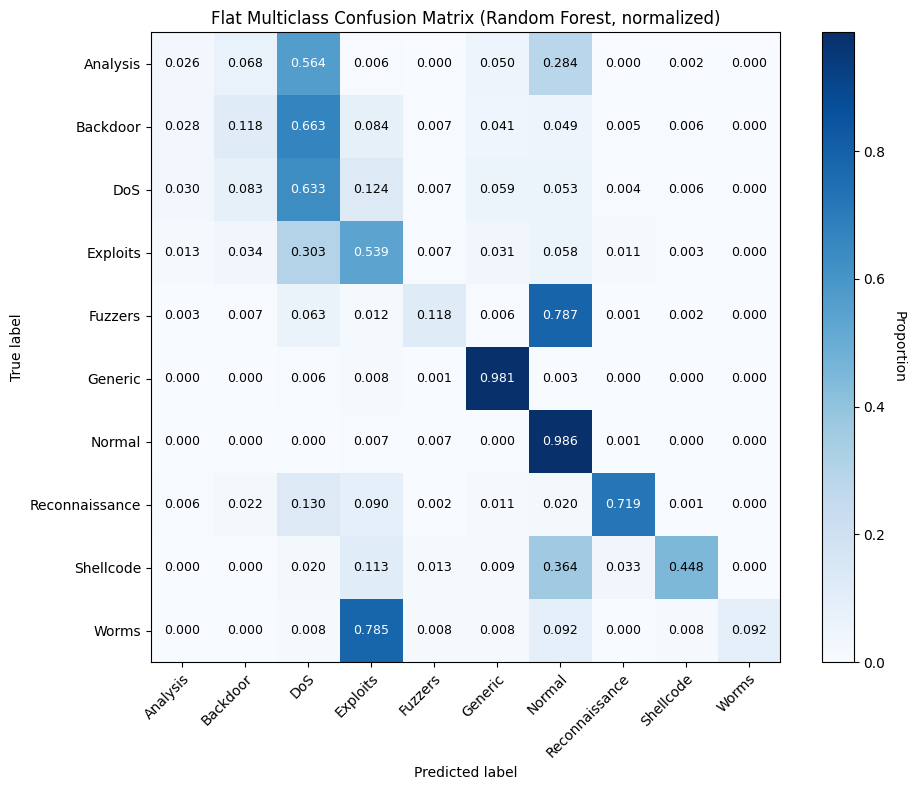

In [40]:
# =========================
# STEP 6.D.2 — Confusion matrix (RF)
# =========================
def plot_confusion_matrix_pretty(
    cm,
    labels,
    title="Confusion Matrix",
    cmap="Blues",
    figsize=(10, 8),
    normalize=False,
    savepath=None
):
    """
    Pretty confusion matrix with annotations.
    Optionally normalize by true class counts.
    """

    if normalize:
        cm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
        cm_display = np.round(cm, 3)
    else:
        cm_display = cm

    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(cm_display, interpolation="nearest", cmap=cmap)

    cbar = fig.colorbar(im, ax=ax)
    cbar.ax.set_ylabel("Count" if not normalize else "Proportion", rotation=270, labelpad=15)

    ax.set(
        xticks=np.arange(len(labels)),
        yticks=np.arange(len(labels)),
        xticklabels=labels,
        yticklabels=labels,
        xlabel="Predicted label",
        ylabel="True label",
        title=title,
    )

    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    # Annotate cells
    thresh = cm_display.max() / 2.0
    for i in range(cm_display.shape[0]):
        for j in range(cm_display.shape[1]):
            value = cm_display[i, j]
            ax.text(
                j, i,
                f"{value:.0f}" if not normalize else f"{value:.3f}",
                ha="center",
                va="center",
                color="white" if value > thresh else "black",
                fontsize=9
            )

    ax.grid(False)
    fig.tight_layout()
    if savepath is not None:
        plt.savefig(savepath, dpi=300, bbox_inches="tight")
    plt.show()


cm = rf_mc_res["ConfusionMatrix"]
plot_confusion_matrix_pretty(
    cm,
    labels_mc,
    title="Flat Multiclass Confusion Matrix (Random Forest, normalized)",
    cmap="Blues",
    normalize=True,
    savepath="cm_flat_rf.png"
)



In [41]:
# =========================
# STEP 7.A — Attack-only multiclass setup
# =========================

attack_mask_train = TRAIN_DF[TARGET_MULTI] != "Normal"
attack_mask_test  = TEST_DF[TARGET_MULTI]  != "Normal"

X_train_attack = X_train[attack_mask_train.values]
X_test_attack  = X_test[attack_mask_test.values]

y_train_attack = y_train_multi[attack_mask_train.values]
y_test_attack  = y_test_multi[attack_mask_test.values]

attack_labels = sorted(np.unique(y_train_attack))

print("Attack-only shapes:")
print("Train:", X_train_attack.shape)
print("Test :", X_test_attack.shape)
print("Classes:", attack_labels)

Attack-only shapes:
Train: (45332, 190)
Test : (119341, 190)
Classes: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']


In [42]:
# =========================
# STEP 7.A — RF on attack-only multiclass
# =========================

rf_attack = RandomForestClassifier(
    n_estimators=200,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

rf_attack_res = eval_multiclass(
    rf_attack,
    X_train_attack,
    y_train_attack,
    X_test_attack,
    y_test_attack,
    attack_labels
)

print("RF attack-only:")
print("Accuracy :", rf_attack_res["Accuracy"])
print("Macro-F1 :", rf_attack_res["Macro-F1"])
print("Weighted-F1:", rf_attack_res["Weighted-F1"])

RF attack-only:
Accuracy : 0.7592445178103083
Macro-F1 : 0.51636075139965
Weighted-F1: 0.7704401821424168


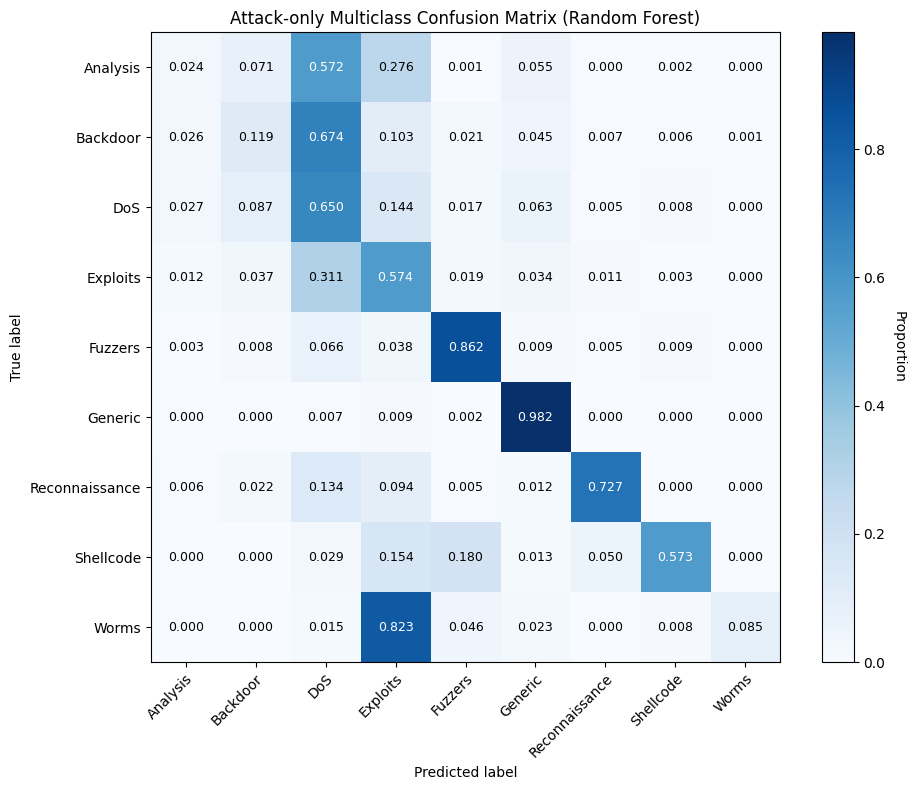

In [43]:
plot_confusion_matrix_pretty(
    rf_attack_res["ConfusionMatrix"],
    attack_labels,
    title="Attack-only Multiclass Confusion Matrix (Random Forest)",
    normalize=True,
    savepath="cm_attackonly_rf.png"
)

In [44]:
# =========================
# STEP 7.B — Grouped formulation
# =========================

GROUP_MAP = {
    "Normal": "Normal",
    "Reconnaissance": "Recon",
    "DoS": "DoS",
    "Worms": "DoS",
    "Exploits": "Exploit",
    "Shellcode": "Exploit",
    "Backdoor": "Exploit",
    "Fuzzers": "Fuzzing",
    "Generic": "Generic",
    "Analysis": "Analysis",
}

y_train_group = np.array([GROUP_MAP[y] for y in y_train_multi])
y_test_group  = np.array([GROUP_MAP[y] for y in y_test_multi])

group_labels = sorted(np.unique(y_train_group))
print("Grouped labels:", group_labels)

Grouped labels: ['Analysis', 'DoS', 'Exploit', 'Fuzzing', 'Generic', 'Normal', 'Recon']


In [45]:
rf_group = RandomForestClassifier(
    n_estimators=200,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

rf_group_res = eval_multiclass(
    rf_group,
    X_train,
    y_train_group,
    X_test,
    y_test_group,
    group_labels
)

print("RF grouped:")
print("Accuracy :", rf_group_res["Accuracy"])
print("Macro-F1 :", rf_group_res["Macro-F1"])
print("Weighted-F1:", rf_group_res["Weighted-F1"])

RF grouped:
Accuracy : 0.7488779007762018
Macro-F1 : 0.5702444701487913
Weighted-F1: 0.7292047860533526


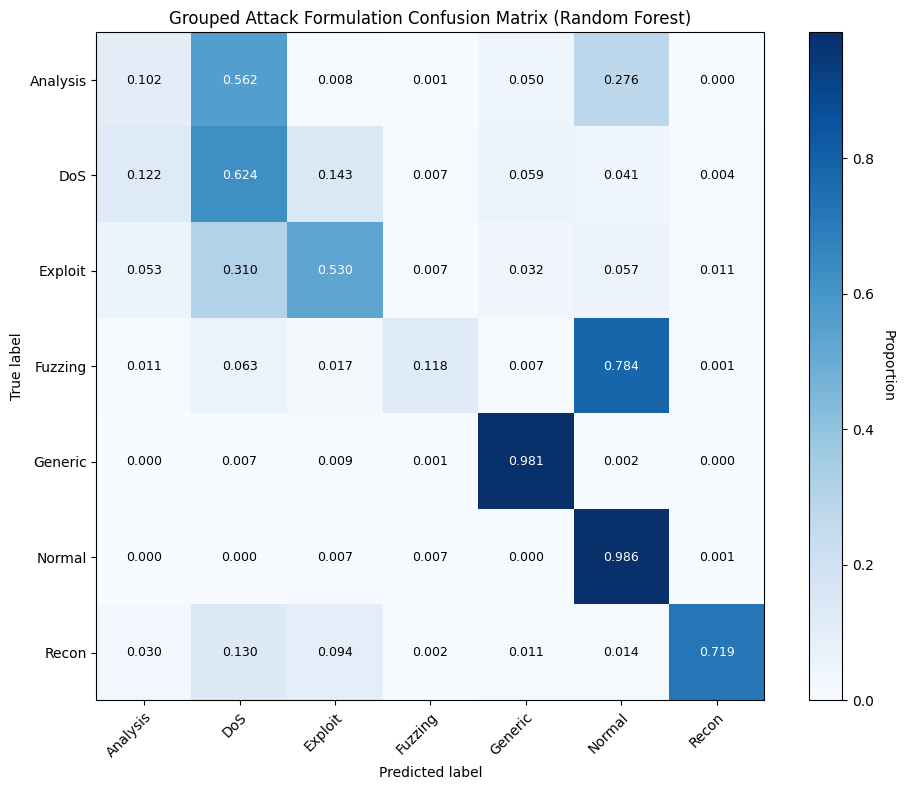

In [46]:
plot_confusion_matrix_pretty(
    rf_group_res["ConfusionMatrix"],
    group_labels,
    title="Grouped Attack Formulation Confusion Matrix (Random Forest)",
    normalize=True,
    savepath="cm_grouped_rf"
)

In [47]:
# =========================
# LR (attack-only)
# =========================

from sklearn.linear_model import LogisticRegression

lr_attack = LogisticRegression(
    max_iter=2000,
    n_jobs=-1,
    class_weight="balanced",
    solver="lbfgs",
    random_state=SEED
)

lr_attack_res = eval_multiclass(
    lr_attack,
    X_train_attack, y_train_attack,
    X_test_attack,  y_test_attack,
    attack_labels
)

print("LR attack-only:")
print("Accuracy :", lr_attack_res["Accuracy"])
print("Macro-F1 :", lr_attack_res["Macro-F1"])
print("Weighted-F1:", lr_attack_res["Weighted-F1"])


C:\Users\rober\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


LR attack-only:
Accuracy : 0.6680771905715555
Macro-F1 : 0.41044589150233357
Weighted-F1: 0.6913974465796312


In [48]:
# =========================
# LR (grouped)
# =========================

lr_group = LogisticRegression(
    max_iter=2000,
    n_jobs=-1,
    class_weight="balanced",
    solver="lbfgs",
    random_state=SEED
)

lr_group_res = eval_multiclass(
    lr_group,
    X_train, y_train_group,
    X_test,  y_test_group,
    group_labels
)

print("LR grouped:")
print("Accuracy :", lr_group_res["Accuracy"])
print("Macro-F1 :", lr_group_res["Macro-F1"])
print("Weighted-F1:", lr_group_res["Weighted-F1"])


C:\Users\rober\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


LR grouped:
Accuracy : 0.7259283339321665
Macro-F1 : 0.5635721916083266
Weighted-F1: 0.7313468741350714


In [49]:

# =========================
# STEP 7.D.1 — ExtraTrees (flat multiclass)
# =========================
from sklearn.ensemble import ExtraTreesClassifier

et_flat = ExtraTreesClassifier(
    n_estimators=200,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

et_flat_res = eval_multiclass(
    et_flat,
    X_train,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc
)

print("ExtraTrees flat:")
print("Accuracy :", et_flat_res["Accuracy"])
print("Macro-F1 :", et_flat_res["Macro-F1"])
print("Weighted-F1:", et_flat_res["Weighted-F1"])


ExtraTrees flat:
Accuracy : 0.7435625438431399
Macro-F1 : 0.47310260201135057
Weighted-F1: 0.7202772145000711


In [50]:
# =========================
# STEP 7.D.2 — ExtraTrees (attack-only)
# =========================

et_attack = ExtraTreesClassifier(
    n_estimators=200,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

et_attack_res = eval_multiclass(
    et_attack,
    X_train_attack,
    y_train_attack,
    X_test_attack,
    y_test_attack,
    attack_labels
)

print("ExtraTrees attack-only:")
print("Accuracy :", et_attack_res["Accuracy"])
print("Macro-F1 :", et_attack_res["Macro-F1"])
print("Weighted-F1:", et_attack_res["Weighted-F1"])


ExtraTrees attack-only:
Accuracy : 0.753764422956067
Macro-F1 : 0.50867475847799
Weighted-F1: 0.7610159504527302


In [51]:
# =========================
# STEP 7.D.3 — ExtraTrees (grouped)
# =========================

et_group = ExtraTreesClassifier(
    n_estimators=200,
    n_jobs=-1,
    class_weight="balanced",
    random_state=SEED
)

et_group_res = eval_multiclass(
    et_group,
    X_train,
    y_train_group,
    X_test,
    y_test_group,
    group_labels
)

print("ExtraTrees grouped:")
print("Accuracy :", et_group_res["Accuracy"])
print("Macro-F1 :", et_group_res["Macro-F1"])
print("Weighted-F1:", et_group_res["Weighted-F1"])

ExtraTrees grouped:
Accuracy : 0.7461574874102463
Macro-F1 : 0.5678352180391613
Weighted-F1: 0.727330877344923


In [52]:
# =========================
# MODEL 4 — SGDClassifier (log_loss)
# =========================

from sklearn.linear_model import SGDClassifier

# =========================
# MODEL 4.A — SGD (flat multiclass)
# =========================

sgd_flat = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=1e-4,
    max_iter=2000,
    tol=1e-3,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

sgd_flat_res = eval_multiclass(
    sgd_flat,
    X_train, y_train_multi,
    X_test,  y_test_multi,
    labels_mc
)

print("SGD flat:")
print("Accuracy :", sgd_flat_res["Accuracy"])
print("Macro-F1 :", sgd_flat_res["Macro-F1"])
print("Weighted-F1:", sgd_flat_res["Weighted-F1"])


SGD flat:
Accuracy : 0.7048779235888925
Macro-F1 : 0.4047488175195496
Weighted-F1: 0.7007623112487684


In [53]:
# =========================
# MODEL 4.B — SGD (attack-only)
# =========================

sgd_attack = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=1e-4,
    max_iter=2000,
    tol=1e-3,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

sgd_attack_res = eval_multiclass(
    sgd_attack,
    X_train_attack, y_train_attack,
    X_test_attack,  y_test_attack,
    attack_labels
)

print("SGD attack-only:")
print("Accuracy :", sgd_attack_res["Accuracy"])
print("Macro-F1 :", sgd_attack_res["Macro-F1"])
print("Weighted-F1:", sgd_attack_res["Weighted-F1"])

SGD attack-only:
Accuracy : 0.6661918368372982
Macro-F1 : 0.3876646357934945
Weighted-F1: 0.6875123792347377


In [54]:
# =========================
# MODEL 4.C — SGD (grouped)
# =========================

sgd_group = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=1e-4,
    max_iter=2000,
    tol=1e-3,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

sgd_group_res = eval_multiclass(
    sgd_group,
    X_train, y_train_group,
    X_test,  y_test_group,
    group_labels
)

print("SGD grouped:")
print("Accuracy :", sgd_group_res["Accuracy"])
print("Macro-F1 :", sgd_group_res["Macro-F1"])
print("Weighted-F1:", sgd_group_res["Weighted-F1"])

SGD grouped:
Accuracy : 0.7244797280727269
Macro-F1 : 0.5466622377289333
Weighted-F1: 0.7186181970858235


In [55]:
# =========================
# MODEL 5 — LinearSVC
# =========================

from sklearn.svm import LinearSVC
# =========================
# MODEL 5.A — LinearSVC (flat multiclass)
# =========================

svc_flat = LinearSVC(
    class_weight="balanced",
    random_state=SEED,
    max_iter=5000
)

svc_flat_res = eval_multiclass(
    svc_flat,
    X_train, y_train_multi,
    X_test,  y_test_multi,
    labels_mc
)

print("LinearSVC flat:")
print("Accuracy :", svc_flat_res["Accuracy"])
print("Macro-F1 :", svc_flat_res["Macro-F1"])
print("Weighted-F1:", svc_flat_res["Weighted-F1"])

LinearSVC flat:
Accuracy : 0.706206762822158
Macro-F1 : 0.40907969251392623
Weighted-F1: 0.702142392894689


In [56]:
# =========================
# MODEL 5.B — LinearSVC (attack-only)
# =========================

svc_attack = LinearSVC(
    class_weight="balanced",
    random_state=SEED,
    max_iter=5000
)

svc_attack_res = eval_multiclass(
    svc_attack,
    X_train_attack, y_train_attack,
    X_test_attack,  y_test_attack,
    attack_labels
)

print("LinearSVC attack-only:")
print("Accuracy :", svc_attack_res["Accuracy"])
print("Macro-F1 :", svc_attack_res["Macro-F1"])
print("Weighted-F1:", svc_attack_res["Weighted-F1"])

LinearSVC attack-only:
Accuracy : 0.6770347156467601
Macro-F1 : 0.40662113475185874
Weighted-F1: 0.6975787775278955


In [57]:
# =========================
# MODEL 5.C — LinearSVC (grouped)
# =========================

svc_group = LinearSVC(
    class_weight="balanced",
    random_state=SEED,
    max_iter=5000
)

svc_group_res = eval_multiclass(
    svc_group,
    X_train, y_train_group,
    X_test,  y_test_group,
    group_labels
)

print("LinearSVC grouped:")
print("Accuracy :", svc_group_res["Accuracy"])
print("Macro-F1 :", svc_group_res["Macro-F1"])
print("Weighted-F1:", svc_group_res["Weighted-F1"])

LinearSVC grouped:
Accuracy : 0.716381222874285
Macro-F1 : 0.5322598798667777
Weighted-F1: 0.7043324777628495


In [58]:
# =========================
# FINAL SUMMARY — Macro-F1 across models & formulations
# =========================

def _pack(res):
    return {
        "Accuracy": float(res["Accuracy"]),
        "Macro-F1": float(res["Macro-F1"]),
        "Weighted-F1": float(res["Weighted-F1"]),
    }

rows = []

# ---- Flat multiclass
rows.append({"Model": "Logistic Regression", "Task": "Flat", **_pack(lr_mc_res)})
rows.append({"Model": "Random Forest",       "Task": "Flat", **_pack(rf_mc_res)})
rows.append({"Model": "ExtraTrees",          "Task": "Flat", **_pack(et_flat_res)})
rows.append({"Model": "SGD (log_loss)",      "Task": "Flat", **_pack(sgd_flat_res)})
rows.append({"Model": "LinearSVC",           "Task": "Flat", **_pack(svc_flat_res)})

# ---- Attack-only multiclass
rows.append({"Model": "Logistic Regression", "Task": "Attack-only", **_pack(lr_attack_res)})
rows.append({"Model": "Random Forest",       "Task": "Attack-only", **_pack(rf_attack_res)})
rows.append({"Model": "ExtraTrees",          "Task": "Attack-only", **_pack(et_attack_res)})
rows.append({"Model": "SGD (log_loss)",      "Task": "Attack-only", **_pack(sgd_attack_res)})
rows.append({"Model": "LinearSVC",           "Task": "Attack-only", **_pack(svc_attack_res)})

# ---- Grouped formulation
rows.append({"Model": "Logistic Regression", "Task": "Grouped", **_pack(lr_group_res)})
rows.append({"Model": "Random Forest",       "Task": "Grouped", **_pack(rf_group_res)})
rows.append({"Model": "ExtraTrees",          "Task": "Grouped", **_pack(et_group_res)})
rows.append({"Model": "SGD (log_loss)",      "Task": "Grouped", **_pack(sgd_group_res)})
rows.append({"Model": "LinearSVC",           "Task": "Grouped", **_pack(svc_group_res)})

summary_long = pd.DataFrame(rows)

# Pivot to a compact Macro-F1 table
macro_pivot = summary_long.pivot(index="Model", columns="Task", values="Macro-F1")

# Deltas to highlight formulation effect
macro_pivot["Δ(Grouped-Flat)"] = macro_pivot["Grouped"] - macro_pivot["Flat"]
macro_pivot["Δ(AttackOnly-Flat)"] = macro_pivot["Attack-only"] - macro_pivot["Flat"]

# Sort by formulation gain
macro_pivot_sorted = macro_pivot.sort_values("Δ(Grouped-Flat)", ascending=False)

print("=== Macro-F1 summary (higher is better) ===")
display(macro_pivot_sorted)

# Full table with Accuracy/Weighted-F1 too (optional)
full_pivot = summary_long.pivot_table(
    index="Model",
    columns="Task",
    values=["Accuracy", "Macro-F1", "Weighted-F1"]
).sort_index(axis=1)

print("\n=== Full metrics summary (optional) ===")
display(full_pivot)


=== Macro-F1 summary (higher is better) ===


Task,Attack-only,Flat,Grouped,Δ(Grouped-Flat),Δ(AttackOnly-Flat)
Model,,,,,
SGD (log_loss),0.387665,0.404749,0.546662,0.141913,-0.017084
Logistic Regression,0.410446,0.425604,0.563572,0.137969,-0.015158
LinearSVC,0.406621,0.409080,0.532260,0.123180,-0.002459
Random Forest,0.516361,0.474935,0.570244,0.095309,0.041426
ExtraTrees,0.508675,0.473103,0.567835,0.094733,0.035572



=== Full metrics summary (optional) ===


Accuracy                        Macro-F1            \
Task                Attack-only      Flat   Grouped Attack-only      Flat   
Model                                                                       
ExtraTrees             0.753764  0.743563  0.746157    0.508675  0.473103   
LinearSVC              0.677035  0.706207  0.716381    0.406621  0.409080   
Logistic Regression    0.668077  0.708716  0.725928    0.410446  0.425604   
Random Forest          0.759245  0.745291  0.748878    0.516361  0.474935   
SGD (log_loss)         0.666192  0.704878  0.724480    0.387665  0.404749   

                              Weighted-F1                      
Task                  Grouped Attack-only      Flat   Grouped  
Model                                                          
ExtraTrees           0.567835    0.761016  0.720277  0.727331  
LinearSVC            0.532260    0.697579  0.702142  0.704332  
Logistic Regression  0.563572    0.691397  0.726704  0.731347  
Random Forest        0.570244    0.770440  0.721897  0.729205  
SGD (log_loss)       0.546662    0.687512  0.700762  0.718618

In [59]:
def eval_hierarchical(
    bin_model,
    mc_model,
    X_train,
    y_train_bin,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc,
):
    """
    End-to-end hierarchical evaluation:
    Stage 1: binary (attack vs normal)
    Stage 2: multiclass (attack categories, trained on attack-only data)
    """

    # ------------------
    # Stage 1: Binary
    # ------------------
    bin_model.fit(X_train, y_train_bin)
    y_hat_bin = bin_model.predict(X_test)

    # ------------------
    # Stage 2: Multiclass (attack-only training)
    # ------------------
    attack_train_mask = (y_train_bin == 1)

    X_train_attack = X_train[attack_train_mask]
    y_train_attack = y_train_multi[attack_train_mask]

    mc_model.fit(X_train_attack, y_train_attack)

    # ------------------
    # End-to-end prediction
    # ------------------
    y_hat_final = np.array(["Normal"] * len(y_test_multi), dtype=object)

    attack_idx = np.where(y_hat_bin == 1)[0]
    if len(attack_idx) > 0:
        y_hat_attack = mc_model.predict(X_test[attack_idx])
        y_hat_final[attack_idx] = y_hat_attack

    # ------------------
    # Metrics
    # ------------------
    out = {
        "Accuracy": accuracy_score(y_test_multi, y_hat_final),
        "Macro-F1": f1_score(y_test_multi, y_hat_final, average="macro"),
        "Weighted-F1": f1_score(y_test_multi, y_hat_final, average="weighted"),
        "ConfusionMatrix": confusion_matrix(y_test_multi, y_hat_final, labels=labels_mc),
        "ReportDict": classification_report(
            y_test_multi,
            y_hat_final,
            output_dict=True,
            zero_division=0
        ),
        "Pred": y_hat_final
    }

    return out


In [60]:
rf_bin = RandomForestClassifier(
    n_estimators=250,
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED
)

rf_mc = RandomForestClassifier(
    n_estimators=250,
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED
)

rf_hier_res = eval_hierarchical(
    rf_bin,
    rf_mc,
    X_train,
    y_train_bin,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc
)

print("RF hierarchical:")
print("Accuracy :", rf_hier_res["Accuracy"])
print("Macro-F1 :", rf_hier_res["Macro-F1"])
print("Weighted-F1:", rf_hier_res["Weighted-F1"])


RF hierarchical:
Accuracy : 0.7508340890037127
Macro-F1 : 0.48574883368431643
Weighted-F1: 0.7339255572347069


In [61]:
# =========================
# STEP 6.C — Hierarchical ExtraTrees
# =========================

from sklearn.ensemble import ExtraTreesClassifier

et_bin = ExtraTreesClassifier(
    n_estimators=300,
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED
)

et_mc = ExtraTreesClassifier(
    n_estimators=300,
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED
)

et_hier_res = eval_hierarchical(
    et_bin,
    et_mc,
    X_train,
    y_train_bin,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc
)

print("ExtraTrees hierarchical:")
print("Accuracy :", et_hier_res["Accuracy"])
print("Macro-F1 :", et_hier_res["Macro-F1"])
print("Weighted-F1:", et_hier_res["Weighted-F1"])


ExtraTrees hierarchical:
Accuracy : 0.7457582653229992
Macro-F1 : 0.4762838553137452
Weighted-F1: 0.7253885096513394


In [62]:
# =========================
# STEP 6.C — Hierarchical Logistic Regression
# =========================

from sklearn.linear_model import LogisticRegression

lr_bin = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED
)

lr_mc = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED
)

lr_hier_res = eval_hierarchical(
    lr_bin,
    lr_mc,
    X_train,
    y_train_bin,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc
)

print("Logistic Regression hierarchical:")
print("Accuracy :", lr_hier_res["Accuracy"])
print("Macro-F1 :", lr_hier_res["Macro-F1"])
print("Weighted-F1:", lr_hier_res["Weighted-F1"])


C:\Users\rober\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\rober\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Logistic Regression hierarchical:
Accuracy : 0.6888862274083073
Macro-F1 : 0.38752552361984305
Weighted-F1: 0.6653796443273321


In [63]:
# =========================
# STEP 6.C — Hierarchical LinearSVC
# =========================

from sklearn.svm import LinearSVC

svc_bin = LinearSVC(
    class_weight="balanced",
    random_state=SEED
)

svc_mc = LinearSVC(
    class_weight="balanced",
    random_state=SEED
)

svc_hier_res = eval_hierarchical(
    svc_bin,
    svc_mc,
    X_train,
    y_train_bin,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc
)

print("LinearSVC hierarchical:")
print("Accuracy :", svc_hier_res["Accuracy"])
print("Macro-F1 :", svc_hier_res["Macro-F1"])
print("Weighted-F1:", svc_hier_res["Weighted-F1"])

LinearSVC hierarchical:
Accuracy : 0.6835195419211707
Macro-F1 : 0.3613369867408242
Weighted-F1: 0.6565767969630275


In [64]:
# =========================
# STEP 6.C — Hierarchical SGD (log_loss)
# =========================

from sklearn.linear_model import SGDClassifier

sgd_bin = SGDClassifier(
    loss="log_loss",
    class_weight="balanced",
    max_iter=2000,
    random_state=SEED
)

sgd_mc = SGDClassifier(
    loss="log_loss",
    class_weight="balanced",
    max_iter=2000,
    random_state=SEED
)

sgd_hier_res = eval_hierarchical(
    sgd_bin,
    sgd_mc,
    X_train,
    y_train_bin,
    y_train_multi,
    X_test,
    y_test_multi,
    labels_mc
)

print("SGD hierarchical:")
print("Accuracy :", sgd_hier_res["Accuracy"])
print("Macro-F1 :", sgd_hier_res["Macro-F1"])
print("Weighted-F1:", sgd_hier_res["Weighted-F1"])


SGD hierarchical:
Accuracy : 0.6830518817618241
Macro-F1 : 0.3559241521317575
Weighted-F1: 0.6614903099456769


In [65]:
# =========================
# TABLE — Hierarchical (end-to-end) results across models
# =========================

import pandas as pd

def _pack_mc(res):
    return {
        "Accuracy": float(res["Accuracy"]),
        "Macro-F1": float(res["Macro-F1"]),
        "Weighted-F1": float(res["Weighted-F1"]),
    }

rows = [
    {"Model": "Random Forest",       **_pack_mc(rf_hier_res)},
    {"Model": "ExtraTrees",          **_pack_mc(et_hier_res)},
    {"Model": "Logistic Regression", **_pack_mc(lr_hier_res)},
    {"Model": "Linear SVM",          **_pack_mc(svc_hier_res)},
    {"Model": "SGD (log_loss)",      **_pack_mc(sgd_hier_res)},
]

hier_table = pd.DataFrame(rows).set_index("Model").sort_values("Macro-F1", ascending=False)

print("=== Hierarchical (binary → attack attribution) results ===")
display(hier_table)

# Optional: LaTeX export (copy into Overleaf)
print("\n--- LaTeX (rounded to 3 decimals) ---")
print(hier_table.round(3).to_latex(
    index=True,
    escape=False,
    column_format="lccc"
))

=== Hierarchical (binary → attack attribution) results ===


,Accuracy,Macro-F1,Weighted-F1
Model,,,
Random Forest,0.750834,0.485749,0.733926
ExtraTrees,0.745758,0.476284,0.725389
Logistic Regression,0.688886,0.387526,0.665380
Linear SVM,0.683520,0.361337,0.656577
SGD (log_loss),0.683052,0.355924,0.661490



--- LaTeX (rounded to 3 decimals) ---
\begin{tabular}{lccc}
\toprule
{} &  Accuracy &  Macro-F1 &  Weighted-F1 \\
Model               &           &           &              \\
\midrule
Random Forest       &     0.751 &     0.486 &        0.734 \\
ExtraTrees          &     0.746 &     0.476 &        0.725 \\
Logistic Regression &     0.689 &     0.388 &        0.665 \\
Linear SVM          &     0.684 &     0.361 &        0.657 \\
SGD (log_loss)      &     0.683 &     0.356 &        0.661 \\
\bottomrule
\end{tabular}



C:\Users\rober\AppData\Local\Temp\ipykernel_14812\3082947250.py:29: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  print(hier_table.round(3).to_latex(


In [66]:
# =========================
# FINAL TABLE — Macro-F1 across all formulations
# =========================

import pandas as pd

rows = []

def add_row(model, flat, hier, attack, grouped):
    rows.append({
        "Model": model,
        "Flat": flat["Macro-F1"],
        "Hierarchical": hier["Macro-F1"],
        "Attack-only": attack["Macro-F1"],
        "Grouped": grouped["Macro-F1"],
    })

add_row("Random Forest", rf_mc_res, rf_hier_res, rf_attack_res, rf_group_res)
add_row("ExtraTrees", et_flat_res, et_hier_res, et_attack_res, et_group_res)
add_row("Logistic Regression", lr_mc_res, lr_hier_res, lr_attack_res, lr_group_res)
add_row("Linear SVM", svc_flat_res, svc_hier_res, svc_attack_res, svc_group_res)
add_row("SGD (log_loss)", sgd_flat_res, sgd_hier_res, sgd_attack_res, sgd_group_res)

df_macro = pd.DataFrame(rows).set_index("Model")

# Add deltas
df_macro["Δ(Grouped–Flat)"] = df_macro["Grouped"] - df_macro["Flat"]
df_macro["Δ(Hierarchical–Flat)"] = df_macro["Hierarchical"] - df_macro["Flat"]

# Sort by grouped gain (main claim)
df_macro_sorted = df_macro.sort_values("Δ(Grouped–Flat)", ascending=False)

print("=== Macro-F1 across formulations (higher is better) ===")
display(df_macro_sorted.round(3))

# -------- LaTeX export --------
print("\n--- LaTeX (rounded to 3 decimals) ---")
print(
    df_macro_sorted.round(3).to_latex(
        index=True,
        escape=False,
        column_format="lcccccc"
    )
)

=== Macro-F1 across formulations (higher is better) ===


,Flat,Hierarchical,Attack-only,Grouped,Δ(Grouped–Flat),Δ(Hierarchical–Flat)
Model,,,,,,
SGD (log_loss),0.405,0.356,0.388,0.547,0.142,-0.049
Logistic Regression,0.426,0.388,0.410,0.564,0.138,-0.038
Linear SVM,0.409,0.361,0.407,0.532,0.123,-0.048
Random Forest,0.475,0.486,0.516,0.570,0.095,0.011
ExtraTrees,0.473,0.476,0.509,0.568,0.095,0.003



--- LaTeX (rounded to 3 decimals) ---
\begin{tabular}{lcccccc}
\toprule
{} &   Flat &  Hierarchical &  Attack-only &  Grouped &  Δ(Grouped–Flat) &  Δ(Hierarchical–Flat) \\
Model               &        &               &              &          &                  &                       \\
\midrule
SGD (log_loss)      &  0.405 &         0.356 &        0.388 &    0.547 &            0.142 &                -0.049 \\
Logistic Regression &  0.426 &         0.388 &        0.410 &    0.564 &            0.138 &                -0.038 \\
Linear SVM          &  0.409 &         0.361 &        0.407 &    0.532 &            0.123 &                -0.048 \\
Random Forest       &  0.475 &         0.486 &        0.516 &    0.570 &            0.095 &                 0.011 \\
ExtraTrees          &  0.473 &         0.476 &        0.509 &    0.568 &            0.095 &                 0.003 \\
\bottomrule
\end{tabular}



C:\Users\rober\AppData\Local\Temp\ipykernel_14812\3639140804.py:39: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  df_macro_sorted.round(3).to_latex(


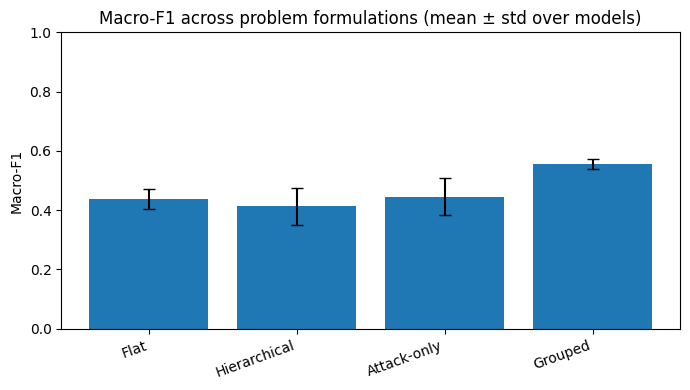

In [67]:
cols = ["Flat", "Hierarchical", "Attack-only", "Grouped"]
means = df_macro[cols].mean()
stds  = df_macro[cols].std()

plt.figure(figsize=(7, 4))
plt.bar(means.index, means.values, yerr=stds.values, capsize=4)
plt.ylabel("Macro-F1")
plt.ylim(0, 1.0)
plt.xticks(rotation=20, ha="right")
plt.title("Macro-F1 across problem formulations (mean ± std over models)")
plt.tight_layout()

plt.savefig("macro_f1_by_formulation.png", dpi=300, bbox_inches="tight")
plt.show()
